In [6]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random
import pandas as pd

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

# 生成BA无标度网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
def generate_ba_scale_free_network(N, m):
    G = nx.barabasi_albert_graph(N, m)
    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(1, 10)
    W = nx.to_numpy_array(G, weight='weight')
    return W

# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

# 计算M^1矩阵
def calculate_M1_matrix(C, n, p):
    N = C.shape[0]
    M1 = np.zeros_like(C, dtype=float)
    for i in range(N):
        for j in range(N):
            delta_ij = 1 if i == j else 0
            term1 = (1 - p)**2 * delta_ij * n[j]
            term2 = p * (1 - p) * n[j] * (C[i, j] + C[j, i])
            term3 = p**2 * n[j] * np.dot(C[i, :], C[:, j])
            M1[i, j] = term1 + term2 + term3
    return M1

# 计算 \beta_c 并保存特征值和 beta_c 的计算步骤
def calculate_beta_c(M, mu, p):
    eigenvalues = np.linalg.eigvals(M)  # 计算M矩阵的特征值
    eigenvalues_real = np.real(eigenvalues)  # 取特征值的实部，避免复数值
    lambda_max = np.max(eigenvalues_real)    # 找到最大特征值
    beta_c = mu / lambda_max  # 根据公式计算beta_c
    return lambda_max, beta_c

# 初始变量
N = 22
m = 5

mu = 0.1  # 恢复率
p_move_values = np.concatenate([
    np.arange(0.01, 0.1, 0.01),
    np.arange(0.1, 1.01, 0.01)
])


# 方法一：生成BA无标度网络
W = generate_ba_scale_free_network(N, m)

# 方法二：计算C矩阵
C = calculate_C_matrix(W)

# 方法三：生成k和n的值
n = np.full(N, 50)  # 每个子种群规模

# 记录所有的lambda_max和beta_c
all_results = []

# 计算在不同 alpha 和 p_move 下的beta_c和lambda_max
for p_move in p_move_values:
    # 计算M^1和M^2
    M = calculate_M1_matrix(C, n, p_move)
    
    # 根据公式计算beta_c
    lambda_max, beta_c = calculate_beta_c(M, mu, p_move)
    
    # 保存结果
    all_results.append({
        'p_move': p_move,
        'lambda_max': lambda_max,
        'beta_c': beta_c
    })

# 将结果保存为CSV文件
df = pd.DataFrame(all_results)
df.to_csv('1012_test_results.csv', index=False)

# 打印提示信息
print("特征值 λ_max 和 β_c 的计算结果已保存到CSV文件中。")


特征值 λ_max 和 β_c 的计算结果已保存到CSV文件中。


d:\Anaconda3\envs\complex\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
d:\Anaconda3\envs\complex\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
d:\Anaconda3\envs\complex\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
d:\Anaconda3\envs\complex\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with

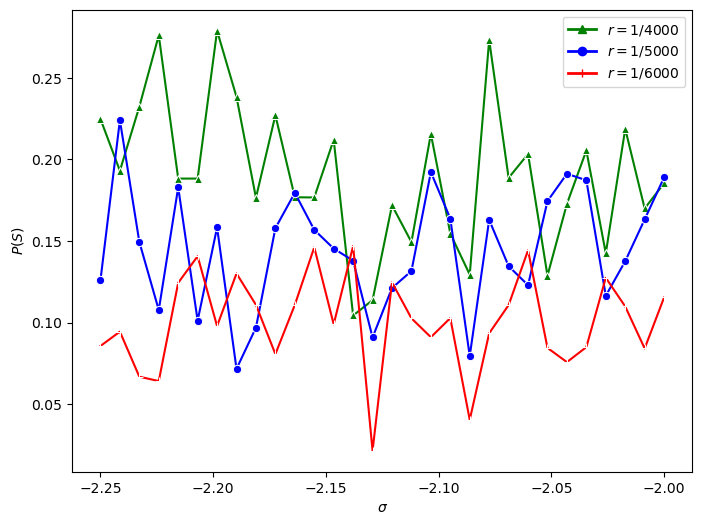

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

# 示例数据
x = np.linspace(-2.25, -2.0, 30)
y1 = np.random.normal(0.2, 0.05, len(x))
y2 = np.random.normal(0.15, 0.04, len(x))
y3 = np.random.normal(0.1, 0.03, len(x))

# 创建图形
plt.figure(figsize=(8, 6))

# 绘制带标记的折线图
sns.lineplot(x=x, y=y1, marker='^', color='green', label=r'$r=1/4000$')
sns.lineplot(x=x, y=y2, marker='o', color='blue', label=r'$r=1/5000$')
sns.lineplot(x=x, y=y3, marker='+', color='red', label=r'$r=1/6000$')

# 自定义图例
legend_elements = [
    Line2D([0], [0], color='green', lw=2, label=r'$r=1/4000$', marker='^'),
    Line2D([0], [0], color='blue', lw=2, label=r'$r=1/5000$', marker='o'),
    Line2D([0], [0], color='red', lw=2, label=r'$r=1/6000$', marker='+')
]

# 添加自定义图例到图中
plt.legend(handles=legend_elements, loc='upper right')

# 设置坐标轴标签
plt.xlabel(r'$\sigma$')
plt.ylabel(r'$P(S)$')

# 显示图形
plt.show()
